# Task 1 – Image Restoration and Segmentation (Unit 3)

**Input:** my own photograph `data/photo1.jpg`

**What this notebook does**
- **A. Image restoration:** add Gaussian and salt-and-pepper noise, restore with median and Gaussian filters, and compare with the clean image using PSNR and SSIM
- **B. Morphology and segmentation:** Otsu thresholding, erosion, dilation, opening, closing, Canny edge detection and watershed segmentation

All figures and tables are also saved to `outputs/task1/`.

## 0. Setup – imports and helper functions

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from skimage.segmentation import watershed as sk_watershed, mark_boundaries
from skimage.filters import sobel
from skimage.feature import peak_local_max

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

OUT = "outputs/task1"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(42)   # fixed seed so the noise is the same every run


def show(images, titles, cols=3, size=4.0, suptitle=None, save_as=None):
    """Display a grid of images (BGR colour or grayscale) and optionally save it."""
    rows = (len(images) + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size * h / w + 0.45) + 0.5))
    axes = np.array(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap="gray")
        ax.set_title(t, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    if save_as:
        fig.savefig(f"{OUT}/{save_as}", dpi=110)
    plt.show()

## 1. Load the original photograph
The phone photo is about 1932×2576 px. It is resized to 750 px width so processing is fast. The original file is not modified.

Original size (h, w, channels): (2576, 1932, 3)
Working size: (1000, 750, 3)


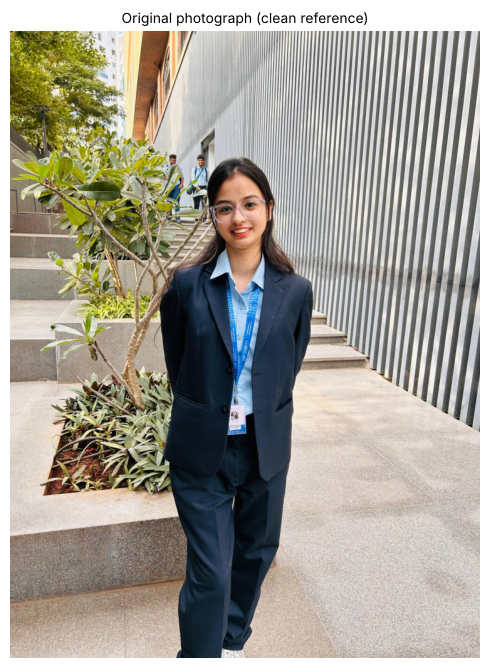

In [2]:
original = cv2.imread("data/photo1.jpg")
print("Original size (h, w, channels):", original.shape)

W = 750
img = cv2.resize(original, (W, int(original.shape[0] * W / original.shape[1])), interpolation=cv2.INTER_AREA)
print("Working size:", img.shape)
show([img], ["Original photograph (clean reference)"], cols=1, size=5)

## A. Image Restoration
### A1. Add noise
- **Gaussian noise:** a random value from a normal distribution (mean 0, σ = 25) is added to every pixel. This models sensor noise.
- **Salt-and-pepper noise:** 5% of the pixels are randomly set to pure black (0) or pure white (255). This models transmission errors or dead pixels.

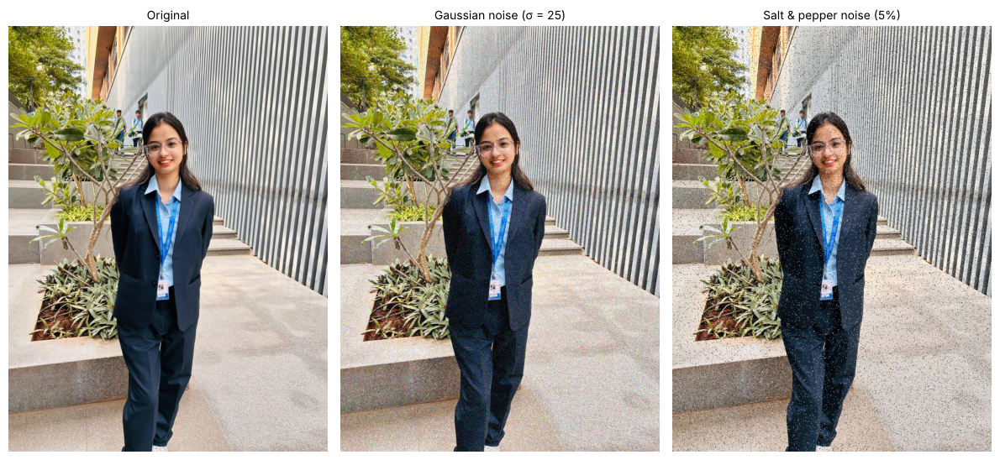

In [3]:
def add_gaussian_noise(image, sigma=25):
    noise = rng.normal(0, sigma, image.shape)
    return np.clip(image.astype(np.float64) + noise, 0, 255).astype(np.uint8)


def add_salt_pepper(image, amount=0.05):
    out = image.copy()
    r = rng.random(image.shape[:2])
    out[r < amount / 2] = 0            # pepper
    out[r > 1 - amount / 2] = 255      # salt
    return out


noisy_gauss = add_gaussian_noise(img)
noisy_sp = add_salt_pepper(img)
cv2.imwrite(f"{OUT}/noisy_gauss.jpg", noisy_gauss)
cv2.imwrite(f"{OUT}/noisy_sp.jpg", noisy_sp)

show([img, noisy_gauss, noisy_sp],
     ["Original", "Gaussian noise (σ = 25)", "Salt & pepper noise (5%)"], cols=3, size=4)

### A2. Restore with median and Gaussian filters
- **Median filter (5×5):** replaces each pixel with the *median* of its neighbourhood. It is non-linear and ignores extreme outliers.
- **Gaussian filter (5×5, σ = 1.5):** replaces each pixel with a *weighted average* of its neighbourhood. It is linear and smooths everything, including edges.

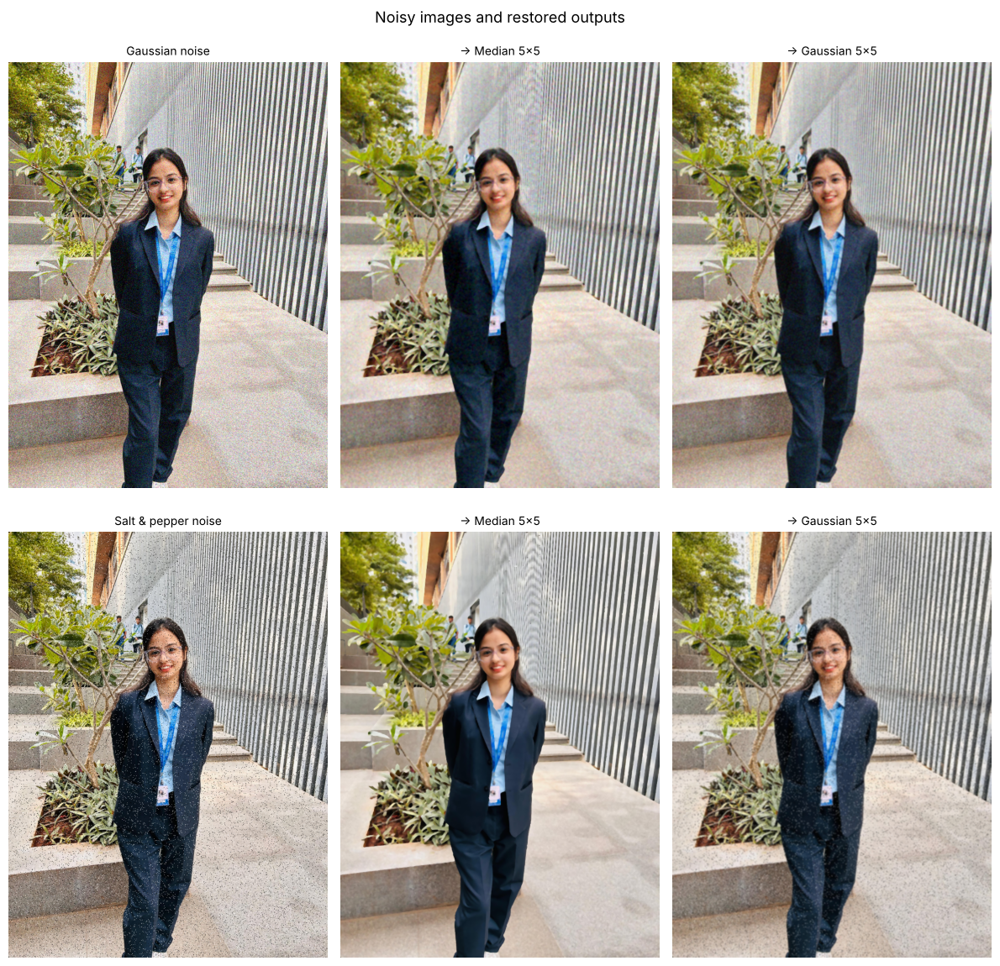

In [4]:
restored = {
    ("Gaussian noise", "Median 5x5"): cv2.medianBlur(noisy_gauss, 5),
    ("Gaussian noise", "Gaussian 5x5"): cv2.GaussianBlur(noisy_gauss, (5, 5), 1.5),
    ("Salt & pepper", "Median 5x5"): cv2.medianBlur(noisy_sp, 5),
    ("Salt & pepper", "Gaussian 5x5"): cv2.GaussianBlur(noisy_sp, (5, 5), 1.5),
}
for (noise, filt), im in restored.items():
    name = f"restored_{'gauss' if 'Gaussian n' in noise else 'sp'}_{filt.split()[0].lower()}.jpg"
    cv2.imwrite(f"{OUT}/{name}", im)

show([noisy_gauss, restored[("Gaussian noise", "Median 5x5")], restored[("Gaussian noise", "Gaussian 5x5")],
      noisy_sp, restored[("Salt & pepper", "Median 5x5")], restored[("Salt & pepper", "Gaussian 5x5")]],
     ["Gaussian noise", "→ Median 5x5", "→ Gaussian 5x5",
      "Salt & pepper noise", "→ Median 5x5", "→ Gaussian 5x5"],
     cols=3, size=4, suptitle="Noisy images and restored outputs", save_as="fig1_restoration.png")

### A3. Zoomed comparison
A close-up of the face shows the difference between the filters more clearly.

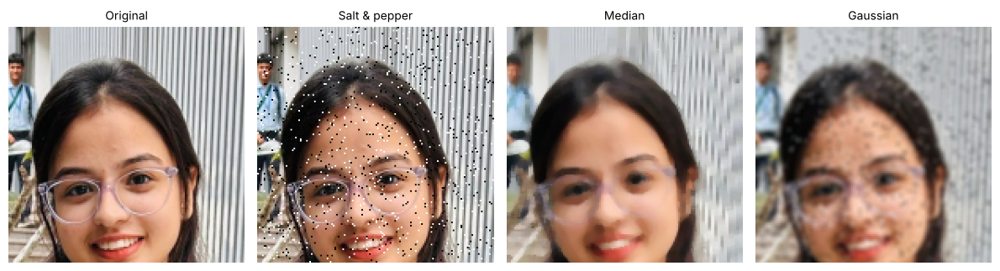

In [5]:
y0, y1, x0, x1 = 180, 330, 300, 450   # face region
crop = lambda im: cv2.resize(im[y0:y1, x0:x1], None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
show([crop(img), crop(noisy_sp), crop(restored[("Salt & pepper", "Median 5x5")]), crop(restored[("Salt & pepper", "Gaussian 5x5")])],
     ["Original", "Salt & pepper", "Median", "Gaussian"], cols=4, size=3, save_as="fig1b_zoom.png")

### A4. Quantitative comparison – PSNR and SSIM
- **PSNR (Peak Signal-to-Noise Ratio, dB):** based on the mean squared error between the clean and the test image. Higher is better.
- **SSIM (Structural Similarity, 0–1):** compares local brightness, contrast and structure, which is closer to human perception. Higher is better, and 1 means identical.

In [6]:
def metrics(clean, test):
    return round(psnr(clean, test, data_range=255), 2), round(ssim(clean, test, channel_axis=2, data_range=255), 4)

rows = []
for noise, noisy in [("Gaussian noise", noisy_gauss), ("Salt & pepper", noisy_sp)]:
    rows.append([noise, "None (noisy input)", *metrics(img, noisy)])
    for filt in ["Median 5x5", "Gaussian 5x5"]:
        rows.append([noise, filt, *metrics(img, restored[(noise, filt)])])

table_restoration = pd.DataFrame(rows, columns=["Noise", "Filter", "PSNR (dB)", "SSIM"])
table_restoration.to_csv(f"{OUT}/table_restoration.csv", index=False)
table_restoration

,Noise,Filter,PSNR (dB),SSIM
0,Gaussian noise,None (noisy input),20.56,0.5311
1,Gaussian noise,Median 5x5,21.99,0.5786
2,Gaussian noise,Gaussian 5x5,22.41,0.6346
3,Salt & pepper,None (noisy input),17.80,0.5325
4,Salt & pepper,Median 5x5,22.75,0.6778
5,Salt & pepper,Gaussian 5x5,21.92,0.5970


**Observation:**
- For **salt-and-pepper noise**, the **median filter** gives the highest PSNR and SSIM. The noisy pixels are extreme outliers, and the median simply discards them while keeping edges sharp. The Gaussian filter averages the black and white dots into grey blotches.
- For **Gaussian noise**, the **Gaussian filter** is best. The noise is spread over every pixel, and weighted averaging cancels it out. The median filter helps less with this kind of noise.
- Conclusion: **choose the filter that matches the noise model.**

## B. Morphological Processing and Segmentation
### B1. Thresholding to a binary image
**Otsu's method** automatically finds the threshold that best separates the grayscale histogram into two classes. I use the inverted result so that dark objects (the suit, the plants) become white foreground.

Otsu threshold selected: 133.0


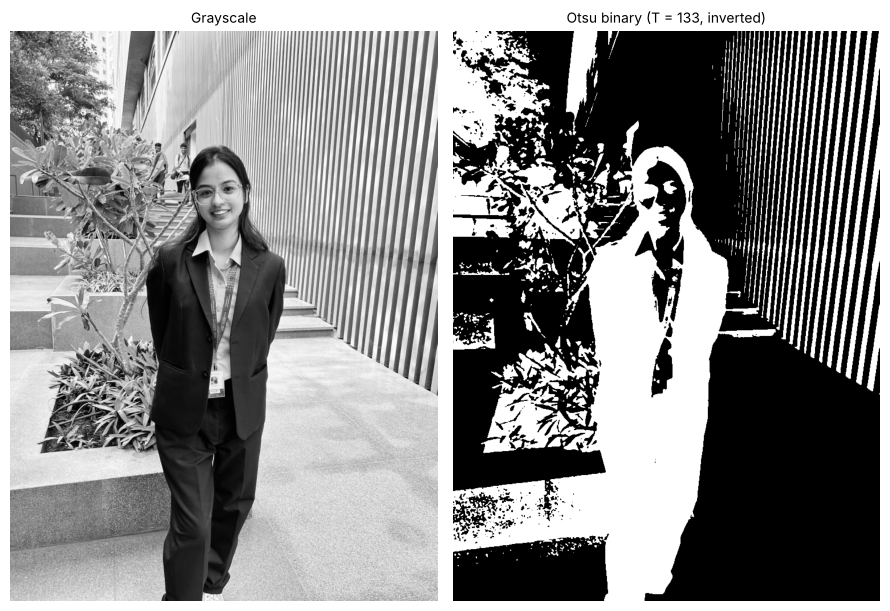

In [7]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
T, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print("Otsu threshold selected:", T)
cv2.imwrite(f"{OUT}/binary_otsu.png", binary)
show([gray, binary], ["Grayscale", f"Otsu binary (T = {T:.0f}, inverted)"], cols=2, size=4.5)

### B2. Erosion, dilation, opening and closing
These use a 7×7 elliptical structuring element.
- **Erosion:** shrinks white regions and removes small white specks.
- **Dilation:** grows white regions and fills small holes and gaps.
- **Opening** (erosion then dilation): removes small noise but keeps the shape of large objects.
- **Closing** (dilation then erosion): fills small holes inside objects but keeps their outline.

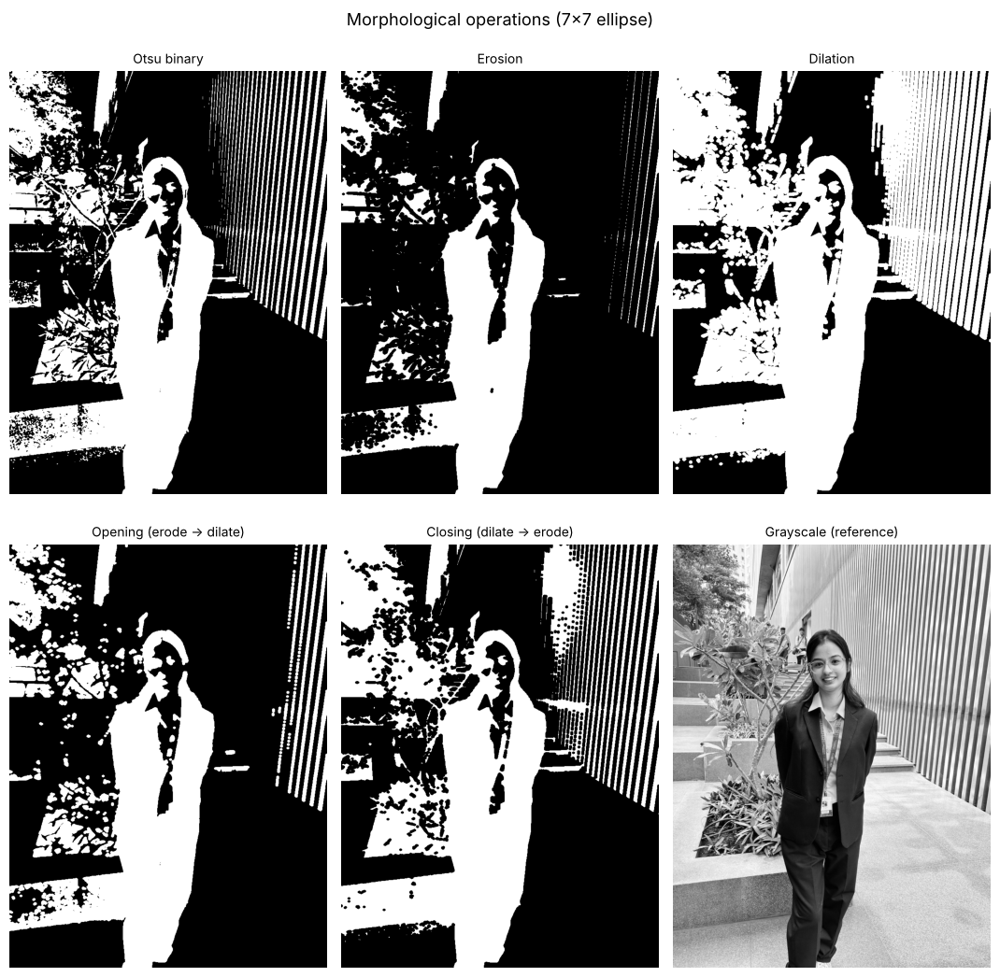

In [8]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
morph = {
    "Erosion": cv2.erode(binary, kernel),
    "Dilation": cv2.dilate(binary, kernel),
    "Opening": cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel),
    "Closing": cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel),
}
for name, m in morph.items():
    cv2.imwrite(f"{OUT}/morph_{name.lower()}.png", m)

show([binary] + list(morph.values()) + [gray],
     ["Otsu binary", "Erosion", "Dilation", "Opening (erode → dilate)", "Closing (dilate → erode)", "Grayscale (reference)"],
     cols=3, size=3.6, suptitle="Morphological operations (7×7 ellipse)", save_as="fig2_morphology.png")

In [9]:
fg_pct = lambda m: round(100 * np.count_nonzero(m) / m.size, 2)
n_components = lambda m: cv2.connectedComponents(m)[0] - 1
table_morph = pd.DataFrame([["Otsu binary", fg_pct(binary), n_components(binary)]] +
                           [[n, fg_pct(m), n_components(m)] for n, m in morph.items()],
                           columns=["Image", "Foreground pixels (%)", "Connected components"])
table_morph.to_csv(f"{OUT}/table_morphology.csv", index=False)
table_morph

,Image,Foreground pixels (%),Connected components
0,Otsu binary,36.39,443
1,Erosion,21.49,332
2,Dilation,54.93,51
3,Opening,29.78,155
4,Closing,40.87,152


**Observation:** erosion cuts the foreground area and removes small specks. Dilation merges regions, so the number of separate components drops sharply. **Opening** removes most of the small noise from the leaves while keeping the person's silhouette, which makes it the best clean-up step for this photo. Closing fills the small holes in the suit.

### B3. Canny edge detection
Canny smooths the image, computes gradients, thins edges with non-maximum suppression, and links them using two thresholds (hysteresis). I compare three variants:
1. Raw grayscale with thresholds 50 and 150
2. Gaussian-blurred image with thresholds 50 and 150
3. Blurred image with *automatic* thresholds (0.66× and 1.33× the median intensity)

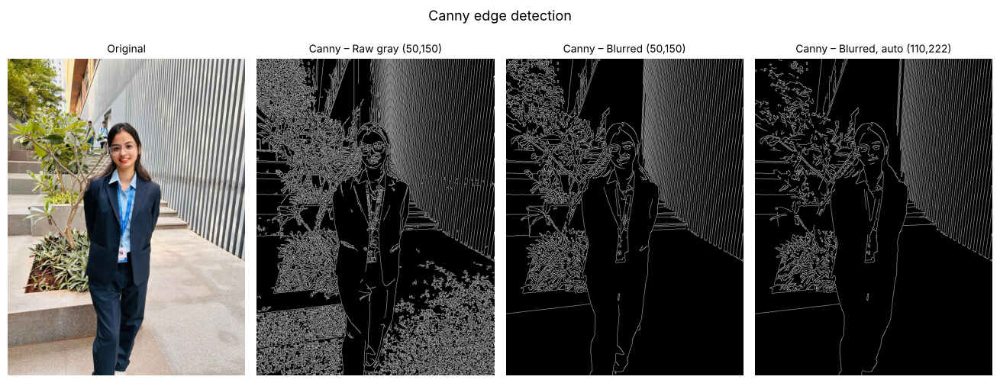

,Canny variant,Edge pixels (%)
0,"Raw gray (50,150)",19.75
1,"Blurred (50,150)",9.32
2,"Blurred, auto (110,222)",7.02


In [10]:
blur14 = cv2.GaussianBlur(gray, (5, 5), 1.4)
v = np.median(blur14)
lo, hi = int(max(0, 0.66 * v)), int(min(255, 1.33 * v))
edges = {
    "Raw gray (50,150)": cv2.Canny(gray, 50, 150),
    "Blurred (50,150)": cv2.Canny(blur14, 50, 150),
    f"Blurred, auto ({lo},{hi})": cv2.Canny(blur14, lo, hi),
}
for i, e in enumerate(edges.values(), 1):
    cv2.imwrite(f"{OUT}/canny_{i}.png", e)

show([img] + list(edges.values()), ["Original"] + [f"Canny – {k}" for k in edges],
     cols=4, size=3.3, suptitle="Canny edge detection", save_as="fig3_canny.png")

table_canny = pd.DataFrame([[k, round(100 * np.count_nonzero(e) / e.size, 2)] for k, e in edges.items()],
                           columns=["Canny variant", "Edge pixels (%)"])
table_canny.to_csv(f"{OUT}/table_canny.csv", index=False)
table_canny

**Observation:** without blurring, Canny marks the floor texture and leaves as edges (about 20% of all pixels). Blurring first removes this texture noise. The automatic thresholds give the cleanest map, keeping the person's outline, the steps and the wall lines.

### B4. Watershed segmentation
Watershed treats the image like a landscape and "floods" it from marker points. Region boundaries form where floods from different markers meet. I use two variants:
1. **Marker-based watershed (OpenCV):** Otsu mask → opening → distance transform → the peaks of the distance transform become "sure foreground" markers.
2. **Gradient watershed (scikit-image):** flood the Sobel gradient image from many local minima. This splits the whole scene into regions.

Objects found by marker-based watershed: 3


Regions found by gradient watershed: 398


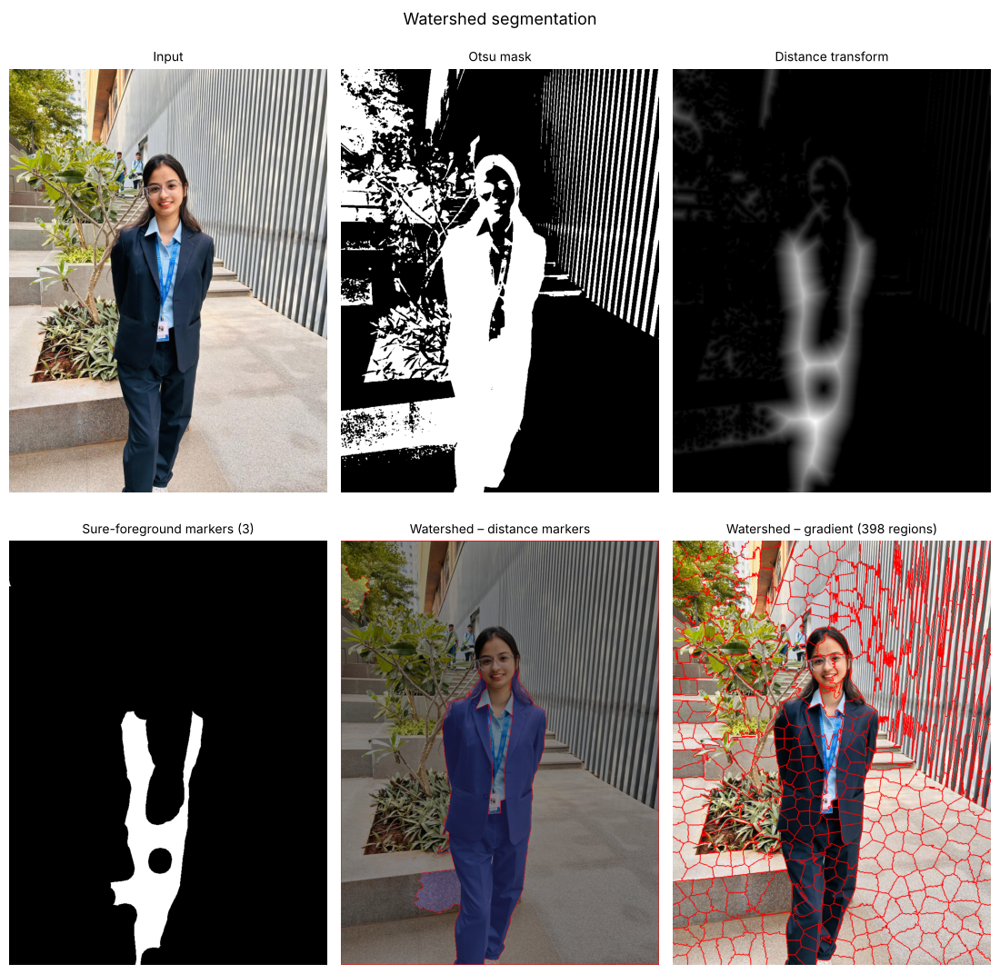

In [11]:
# Variant 1: distance-transform markers (classic OpenCV pipeline)
k3 = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k3, iterations=2)
sure_bg = cv2.dilate(opening, k3, iterations=3)
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist, 0.35 * dist.max(), 255, 0)
sure_fg = sure_fg.astype(np.uint8)
unknown = cv2.subtract(sure_bg, sure_fg)

n_markers, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1            # background becomes 1, not 0
markers[unknown == 255] = 0      # 0 = unknown, to be decided by the flooding
markers = cv2.watershed(img.copy(), markers)

colours = rng.integers(40, 255, (markers.max() + 2, 3), dtype=np.uint8)
colours[1] = 0
ws1 = cv2.addWeighted(img, 0.55, colours[np.clip(markers, 0, None)], 0.45, 0)
ws1[markers == -1] = (0, 0, 255)  # boundaries in red
print("Objects found by marker-based watershed:", n_markers - 1)

# Variant 2: gradient-based watershed
grad = sobel(cv2.GaussianBlur(gray, (7, 7), 0) / 255.0)
coords = peak_local_max(-grad, min_distance=25, exclude_border=False)
mk = np.zeros(gray.shape, dtype=int)
mk[tuple(coords.T)] = np.arange(1, len(coords) + 1)
labels = sk_watershed(grad, mk, compactness=0.001)
ws2 = (mark_boundaries(img[..., ::-1], labels, color=(1, 0, 0)) * 255).astype(np.uint8)[..., ::-1]
print("Regions found by gradient watershed:", labels.max())

cv2.imwrite(f"{OUT}/watershed_distance.jpg", ws1)
cv2.imwrite(f"{OUT}/watershed_gradient.jpg", ws2)
dist_vis = cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show([img, binary, dist_vis, sure_fg, ws1, ws2],
     ["Input", "Otsu mask", "Distance transform", f"Sure-foreground markers ({n_markers - 1})",
      "Watershed – distance markers", f"Watershed – gradient ({labels.max()} regions)"],
     cols=3, size=3.7, suptitle="Watershed segmentation", save_as="fig4_watershed.png")

**Observation:**
- The **marker-based watershed** separates the person (dark suit) cleanly from the background, because the distance transform gives one strong peak inside the body.
- The **gradient watershed** *over-segments*: textured areas such as the floor tiles, the leaves and the ribbed wall break into hundreds of small regions.
- **Limitation:** watershed is designed to split *touching objects* such as coins or cells. My photo has one main object, so the classic "splitting touching objects" effect is limited here. A photo of several touching objects on a plain background would show it better.

## Summary of Task 1
| Operation | Best technique for this photo | Why |
|---|---|---|
| Salt-and-pepper noise | Median filter | Discards outlier pixels and keeps edges |
| Gaussian noise | Gaussian filter | Averaging cancels noise spread over every pixel |
| Binary clean-up | Opening | Removes leaf speckle and keeps the person's shape |
| Edges | Canny on a blurred image with automatic thresholds | Suppresses texture and keeps structural edges |
| Segmentation | Marker-based watershed | Isolates the person; the gradient version over-segments |